# Matrix completion: reconstruct a missing image region

Matrix completion estimates unknown entries of a matrix from the entries that remain. A common assumption is that the matrix has low-rank structure: rows and columns share patterns, so the missing values may be inferred from the observed ones.

We will hide a rectangular region of an image, then iteratively find a low-rank matrix that agrees with the visible pixels. The hidden original will only be used afterward to evaluate the reconstruction.

## 1. Show the original color image

First, view the image before making any changes. For the completion exercise, we will work with a smaller grayscale copy so each pixel is one matrix entry and the SVD calculations stay quick.

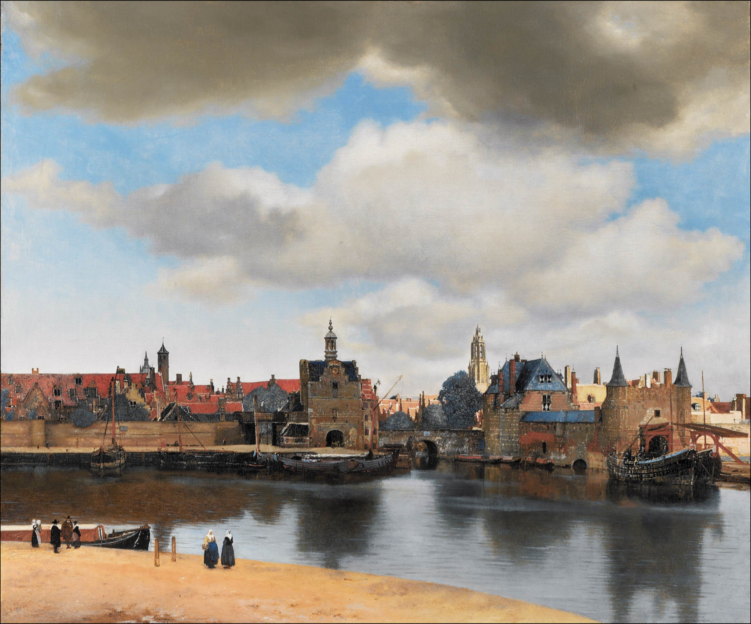

In [1]:
using LinearAlgebra
using Statistics
using Images
using ImageIO

image_path = joinpath(@__DIR__, "..", "images", "view-of-delft.jpg")
original = load(image_path)
original

In [2]:
gray_image = Float64.(Gray.(original[1:2:end, 1:2:end]))
size(gray_image)

(1246, 1500)

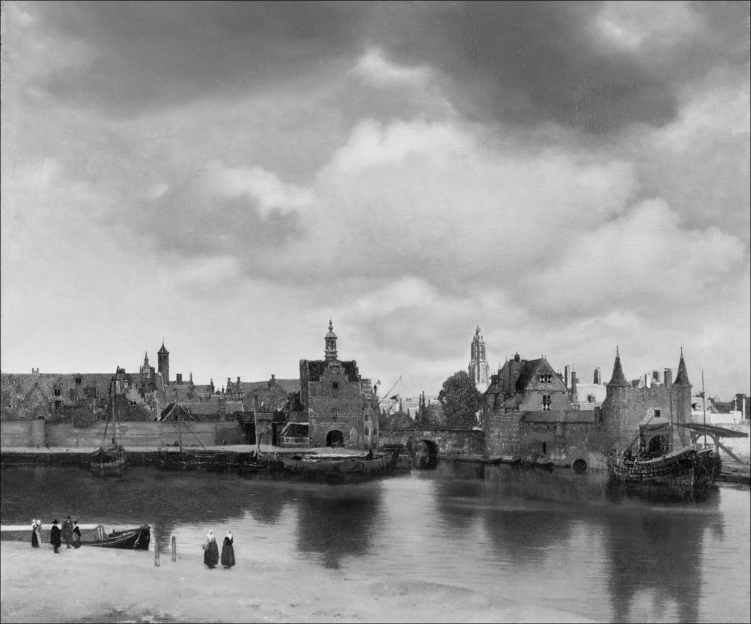

In [3]:
Gray.(gray_image)

## 2. Hide a region

The Boolean mask marks observed entries as `true`. Here we hide a small rectangular patch near the right side of the image. `observed_image` is all the algorithm will receive; the original pixel values in the missing region are excluded from the reconstruction.

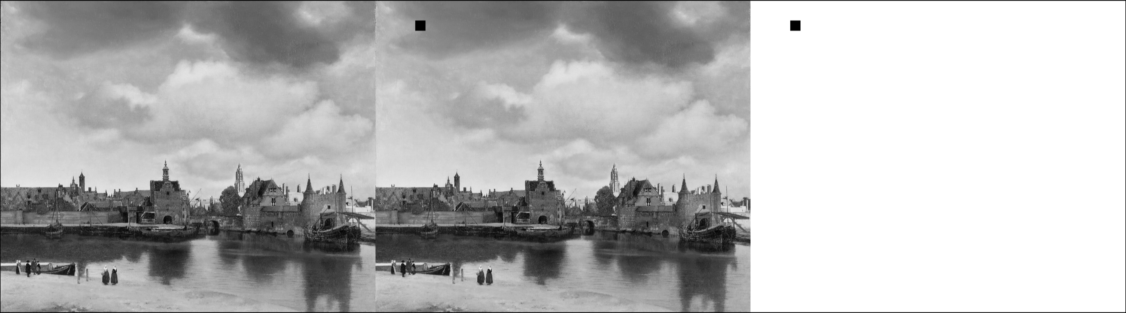

In [4]:
missing_rows = 80:120
missing_cols = 160:200
observed = trues(size(gray_image))
observed[missing_rows, missing_cols] .= false

observed_image = copy(gray_image)
observed_image[.!observed] .= 0.0
hcat(Gray.(gray_image), Gray.(observed_image), Gray.(Float64.(observed)))

The comparison shows the original, the image with the missing region set to black, and the observation mask (white means observed; black means missing). The masked fraction is reported with the reconstruction metrics below. In a real completion task, the hidden values would not be available for evaluation; here we retain the original only so we can measure how well the method did.

## 3. Complete the matrix with a low-rank model

A simple iterative method alternates between two steps: project the current estimate onto matrices of rank at most `k`, then put the observed pixels back exactly. We initialize the missing pixels with the mean of the observed values. This alternating projection is easy to understand, but it is not guaranteed to find the globally best completion.

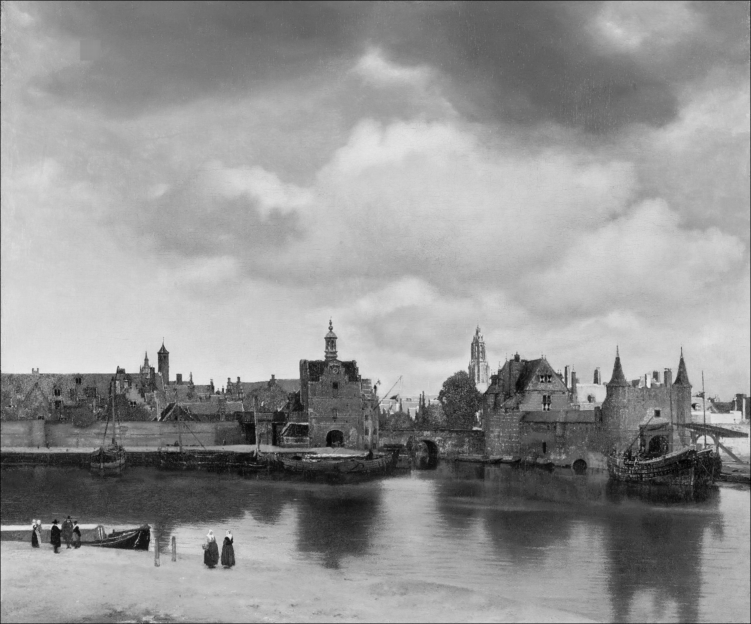

In [5]:
function complete_low_rank(observed_image, observed, rank; iterations=40)
    1 <= rank <= min(size(observed_image)...) || throw(ArgumentError("rank is outside the matrix dimensions"))
    iterations > 0 || throw(ArgumentError("iterations must be positive"))

    estimate = copy(observed_image)
    estimate[.!observed] .= mean(observed_image[observed])

    for _ in 1:iterations
        factors = svd(estimate; full=false)
        low_rank = factors.U[:, 1:rank] * Diagonal(factors.S[1:rank]) * factors.Vt[1:rank, :]
        estimate[.!observed] .= low_rank[.!observed]
        estimate[observed] .= observed_image[observed]
    end

    estimate
end

rank = 6
completed = complete_low_rank(observed_image, observed, rank)
Gray.(clamp.(completed, 0, 1))

The observed pixels are copied back after every low-rank projection, so they remain unchanged. The missing region is filled with values inferred from the global row and column structure of the image. Values may briefly fall outside the usual display range `[0, 1]`; clamping above is only for visualization.

## 4. Compare ranks and measure the missing region

Try a few ranks side by side. A small rank imposes stronger structure; a larger rank allows more detail but can also fit less useful variation. Since the missing block is contiguous and this particular image is not exactly low rank, reconstruction error is not guaranteed to decrease as rank increases.

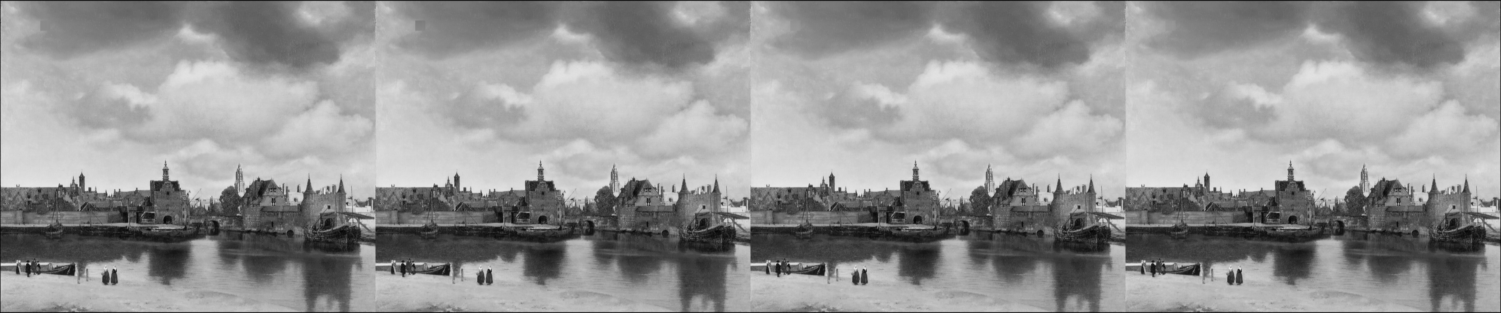

In [6]:
ranks = [2, 3, 5, 8]
completions = [complete_low_rank(observed_image, observed, k) for k in ranks]
hcat((Gray.(clamp.(completion, 0, 1)) for completion in completions)... )

Each panel corresponds to the matching entry in `ranks`, in vector order. Compare the hidden region, not only the surrounding pixels. A low-rank model uses broad patterns across the entire matrix, so it can fill in smooth structure but may miss fine details that cannot be inferred from the visible data.

In [7]:
missing = .!observed
missing_rmse = [sqrt(mean(abs2, gray_image[missing] .- completion[missing])) for completion in completions]
observed_max_error = [maximum(abs.(gray_image[observed] .- completion[observed])) for completion in completions]
mean_fill = fill(mean(observed_image[observed]), size(gray_image))
baseline_rmse = sqrt(mean(abs2, gray_image[missing] .- mean_fill[missing]))
[(rank=ranks[i], missing_region_rmse=missing_rmse[i], observed_max_error=observed_max_error[i]) for i in eachindex(ranks)],
(mean_fill_baseline_rmse=baseline_rmse, masked_fraction=count(missing) / length(missing))

([(rank = 2, missing_region_rmse = 0.0599818652619113, observed_max_error = 0.0), (rank = 3, missing_region_rmse = 0.08768759024099929, observed_max_error = 0.0), (rank = 5, missing_region_rmse = 0.030928036925356183, observed_max_error = 0.0), (rank = 8, missing_region_rmse = 0.026877113257096366, observed_max_error = 0.0)], (mean_fill_baseline_rmse = 0.03326475481856075, masked_fraction = 0.0008994114499732477))

The missing-region RMSE is meaningful here because we kept the original as a reference. `observed_max_error` should be zero: the visible entries are constrained to their original values. The mean-fill baseline is deliberately simple; compare it with the low-rank estimates to see whether the image's global structure provides useful information.

## Your turn

1. Move the missing rectangle to a different part of the image. Which regions are easier to infer from the rest?
2. Change the size of the rectangle. At what point does the missing region become too large to reconstruct reliably?
3. Try different ranks and iteration counts. Does a larger rank always improve the hidden-region estimate?
4. Hide several separated regions instead of one rectangle. How does that change the information available to the low-rank model?

Matrix completion is an inverse problem: many matrices agree with the observed pixels. Low rank is an assumption that makes a useful estimate possible, not a guarantee that the hidden original can be recovered exactly.